# Project 1: Iris Flower Classification

Beginner project. Goal: predict a flower species from four measurements. Run the notebook cells from top to bottom in Google Colab.

## 1. Load and inspect the data
Each row is a flower. The measurements are features; the target is the flower species.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

iris = load_iris(as_frame=True)
df = iris.frame
print('Shape:', df.shape)
display(df.head())
df.info()
print('Missing values:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
Duplicate rows: 1


## 2. Explore the flowers
This scatter plot helps us see how petal measurements differ between species.

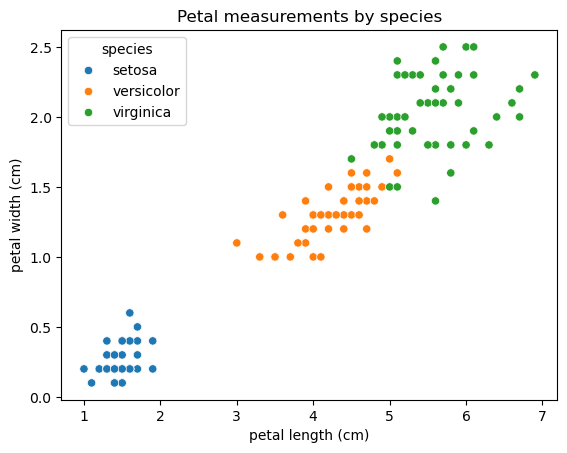

In [2]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)', hue='species')
plt.title('Petal measurements by species')
plt.show()

## 3. Split the data
`X` means input measurements. `y` means the species answer. We keep 20% aside to test the model.

In [3]:
X = df[iris.feature_names]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Training rows: 120 | Test rows: 30


## 4. Train and evaluate
Logistic Regression learns patterns from the training examples. Accuracy is the fraction of test examples predicted correctly.

Test accuracy: 93.33%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



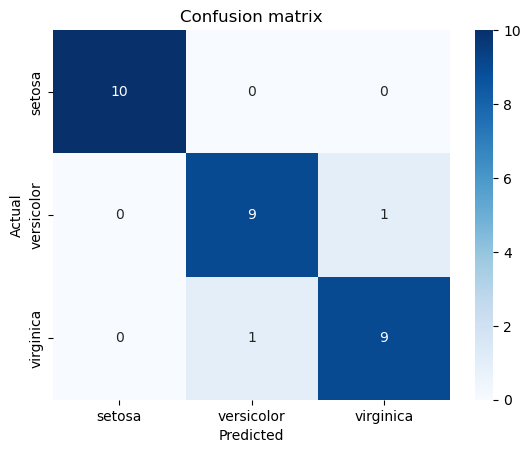

In [4]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f'Test accuracy: {accuracy_score(y_test, pred):.2%}')
print(classification_report(y_test, pred, target_names=iris.target_names))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix'); plt.show()

## 5. Try a new flower
Enter sepal length, sepal width, petal length, petal width—in centimeters.

In [5]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]
answer = model.predict(new_flower)[0]
print('Predicted species:', iris.target_names[answer])

Predicted species: setosa


/home/patil/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 6. Conclusion and improvement
Write down the accuracy you actually got and describe any mistakes in the confusion matrix. This is a small teaching dataset, so real-world data may be harder. **Extra idea:** train a Decision Tree or Random Forest on the same train/test split and compare the results.

**GitHub:** save as `Iris_Flower_Classification.ipynb`, add a README with goal, method, result and run instructions, and use repository name `CodeAlpha_Iris_Flower_Classification`. Run all cells before submitting.